In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap
from geopy.geocoders import Nominatim
import time

# Datos del equipo
team_locations = [
    "Chicago, Illinois, USA",
    "Boulder County, Colorado, USA",
    "Birmingham, Alabama, USA",
    "Sidney, BC, Canada",
    "Guatemala City, Guatemala",
    "Raleigh, North Carolina, USA",
    "Brentwood Bay, BC, Canada",
    "Los Angeles, California, USA"
]

team_members = [
    "Erin Schulze",
    "Drake Swezey",
    "Ashley Daniels",
    "Gescina Richardsen",
    "Hugo Soberaniš",
    "Jack Matson",
    "Curtis Gobbett",
    "Doug Willmore & Nathan Donohoe"
]

# Geocodificar ubicaciones
geolocator = Nominatim(user_agent="team_mapper_v1")
coords = []

print("Obteniendo coordenadas...")
for location, member in zip(team_locations, team_members):
    try:
        loc = geolocator.geocode(location)
        if loc:
            coords.append((loc.latitude, loc.longitude, member, location))
            print(f"✓ {location}: ({loc.latitude:.2f}, {loc.longitude:.2f})")
        time.sleep(1.5)
    except Exception as e:
        print(f"✗ Error con {location}: {e}")

# Crear mapa
plt.figure(figsize=(16, 10))
m = Basemap(projection='merc', resolution='l',
            llcrnrlat=10, urcrnrlat=60,
            llcrnrlon=-130, urcrnrlon=-60)

m.drawcoastlines(linewidth=0.5)
m.drawcountries(linewidth=0.8)
m.fillcontinents(color='#f0f0f0', lake_color='#b3d9ff')
m.drawmapboundary(fill_color='#b3d9ff')
m.drawstates(linewidth=0.3, color='gray')

# Plotear ubicaciones
for lat, lon, member, location in coords:
    x, y = m(lon, lat)
    m.plot(x, y, 'ro', markersize=12, markeredgecolor='darkred', markeredgewidth=1.5)

    # Etiqueta con nombre
    city = location.split(',')[0]
    plt.text(x, y, f'  {member}\n  {city}',
             fontsize=9, ha='left', va='center',
             bbox=dict(boxstyle='round,pad=0.5',
                      facecolor='yellow', alpha=0.85, edgecolor='orange'))

plt.title('Ubicación del Equipo - América del Norte', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n✓ Mapeadas {len(coords)} ubicaciones")

C:\Users\HeyCe\.conda\envs\cartografunk\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


ModuleNotFoundError: No module named 'geopy'

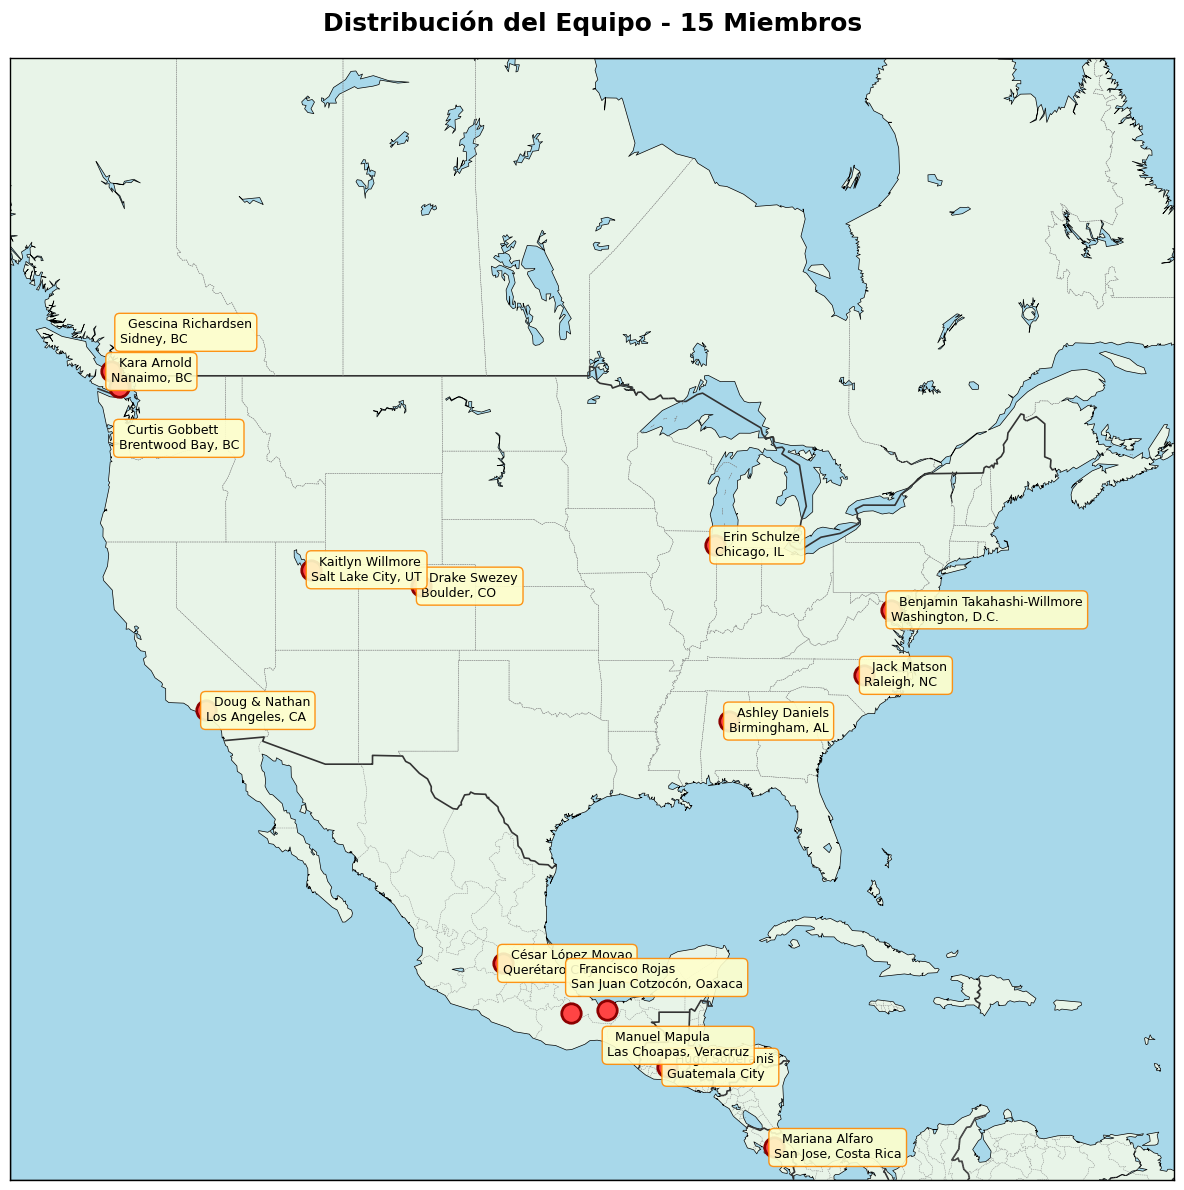


📍 Resumen de ubicaciones:
Total de miembros: 15

Por país:
  🇺🇸 USA: 7
  🇨🇦 Canadá: 3
  🇲🇽 México: 3
  🌎 Centroamérica: 2


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

# Coordenadas del equipo (lat, lon, offset_x, offset_y)
# offset_x y offset_y son para ajustar la posición de la etiqueta
team_data = {
    "Erin Schulze\nChicago, IL": (41.88, -87.63, 0, 0),
    "Drake Swezey\nBoulder, CO": (40.01, -105.27, 0, 0),
    "Ashley Daniels\nBirmingham, AL": (33.52, -86.80, 0, 0),
    "Gescina Richardsen\nSidney, BC": (48.65, -123.40, 0, 1.5),  # offset arriba
    "Hugo Soberaniš\nGuatemala City": (14.64, -90.51, 0, 0),
    "Jack Matson\nRaleigh, NC": (35.78, -78.64, 0, 0),
    "Curtis Gobbett\nBrentwood Bay, BC": (48.55, -123.47, 0, -1.5),  # offset abajo
    "Doug & Nathan\nLos Angeles, CA": (34.05, -118.24, 0, 0),
    "Mariana Alfaro\nSan Jose, Costa Rica": (9.93, -84.08, 0, 0),
    "Benjamin Takahashi-Willmore\nWashington, D.C.": (38.91, -77.04, 0, 0),
    "Kara Arnold\nNanaimo, BC": (49.17, -123.94, 0, 0),
    "Kaitlyn Willmore\nSalt Lake City, UT": (40.76, -111.89, 0, 0),
    "César López Moyao\nQuerétaro City": (20.59, -100.39, 0, 0),
    "Francisco Rojas\nSan Juan Cotzocón, Oaxaca": (17.80, -96.30, 0, 1.2),  # offset arriba
    "Manuel Mapula\nLas Choapas, Veracruz": (17.92, -94.10, 0, -1.2)  # offset abajo
}

# Crear mapa
plt.figure(figsize=(18, 12))
m = Basemap(projection='merc', resolution='l',
            llcrnrlat=8, urcrnrlat=60,
            llcrnrlon=-130, urcrnrlon=-60)

m.drawcoastlines(linewidth=0.5)
m.drawcountries(linewidth=1.2, color='#333333')
m.fillcontinents(color='#e8f4e8', lake_color='#a8d8ea')
m.drawmapboundary(fill_color='#a8d8ea')
m.drawstates(linewidth=0.3, color='gray', linestyle='--')

# Plotear ubicaciones
for label, (lat, lon, offset_x, offset_y) in team_data.items():
    x, y = m(lon, lat)
    m.plot(x, y, 'o', color='#ff4444', markersize=14,
           markeredgecolor='darkred', markeredgewidth=2, zorder=5)

    # Aplicar offset en grados (ajustado para que sea visible)
    x_text, y_text = m(lon + offset_x, lat + offset_y)

    # Determinar alineación basada en offset
    ha = 'right' if offset_x < 0 else 'left'
    va = 'top' if offset_y < 0 else ('bottom' if offset_y > 0 else 'center')

    plt.text(x_text, y_text, f'  {label}',
             fontsize=9, ha=ha, va=va,
             bbox=dict(boxstyle='round,pad=0.4',
                      facecolor='#ffffcc', alpha=0.9, edgecolor='#ff8800'),
             zorder=6)

plt.title(f'Distribución del Equipo - {len(team_data)} Miembros',
          fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Resumen por país/región
print("\n📍 Resumen de ubicaciones:")
print(f"Total de miembros: {len(team_data)}")
print("\nPor país:")
usa = sum(1 for label in team_data.keys() if any(state in label for state in ['IL', 'CO', 'AL', 'NC', 'CA', 'D.C.', 'UT']))
canada = sum(1 for label in team_data.keys() if 'BC' in label)
mexico = sum(1 for label in team_data.keys() if any(state in label for state in ['Querétaro', 'Oaxaca', 'Veracruz']))
centroamerica = sum(1 for label in team_data.keys() if 'Guatemala' in label or 'Costa Rica' in label)
print(f"  🇺🇸 USA: {usa}")
print(f"  🇨🇦 Canadá: {canada}")
print(f"  🇲🇽 México: {mexico}")
print(f"  🌎 Centroamérica: {centroamerica}")

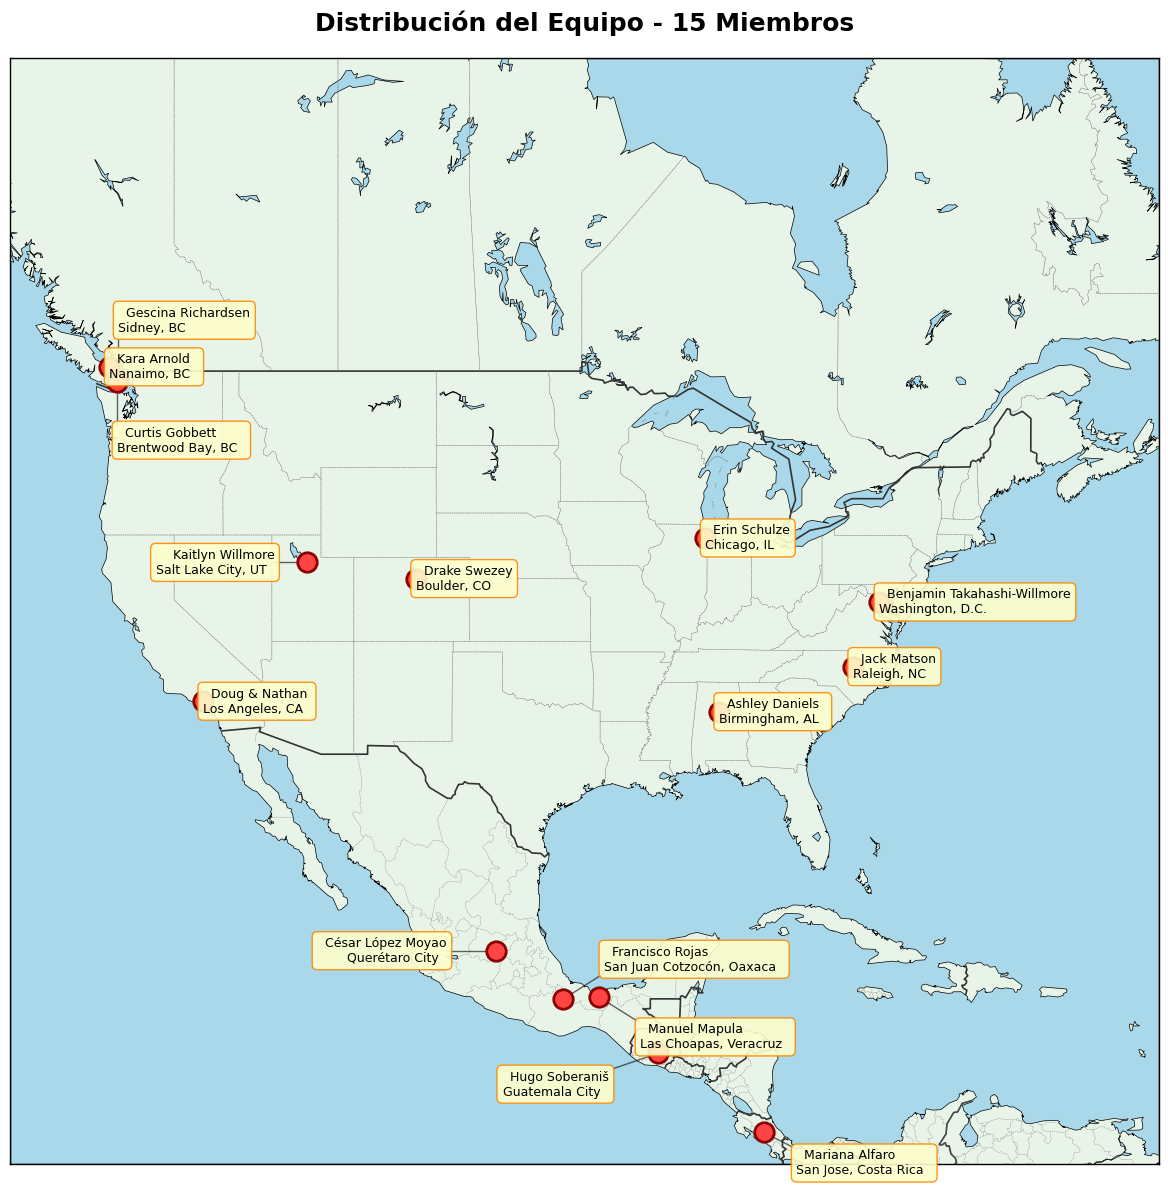


📍 Resumen de ubicaciones:
Total de miembros: 15

Por país:
  🇺🇸 USA: 7
  🇨🇦 Canadá: 3
  🇲🇽 México: 3
  🌎 Centroamérica: 2


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

# Coordenadas del equipo (lat, lon, offset_x, offset_y, ha, va)
# ha: 'left' o 'right' para alineación horizontal
# va: 'top', 'bottom', 'center' para alineación vertical
team_data = {
    "Erin Schulze\nChicago, IL": (41.88, -87.63, 0, 0, 'left', 'center'),
    "Drake Swezey\nBoulder, CO": (40.01, -105.27, 0, 0, 'left', 'center'),
    "Ashley Daniels\nBirmingham, AL": (33.52, -86.80, 0, 0, 'left', 'center'),
    "Gescina Richardsen\nSidney, BC": (48.65, -123.40, 0, 1.8, 'left', 'bottom'),
    "Hugo Soberaniš\nGuatemala City": (14.64, -90.51, -3, -1, 'right', 'top'),
    "Jack Matson\nRaleigh, NC": (35.78, -78.64, 0, 0, 'left', 'center'),
    "Curtis Gobbett\nBrentwood Bay, BC": (48.55, -123.47, 0, -1.8, 'left', 'top'),
    "Doug & Nathan\nLos Angeles, CA": (34.05, -118.24, 0, 0, 'left', 'center'),
    "Mariana Alfaro\nSan Jose, Costa Rica": (9.93, -84.08, 2, -1, 'left', 'top'),
    "Benjamin Takahashi-Willmore\nWashington, D.C.": (38.91, -77.04, 0, 0, 'left', 'center'),
    "Kara Arnold\nNanaimo, BC": (49.17, -123.94, 0, 0, 'left', 'center'),
    "Kaitlyn Willmore\nSalt Lake City, UT": (40.76, -111.89, -2, 0, 'right', 'center'),
    "César López Moyao\nQuerétaro City": (20.59, -100.39, -3, 0, 'right', 'center'),
    "Francisco Rojas\nSan Juan Cotzocón, Oaxaca": (17.80, -96.30, 2.5, 1.5, 'left', 'bottom'),
    "Manuel Mapula\nLas Choapas, Veracruz": (17.92, -94.10, 2.5, -1.5, 'left', 'top')
}

# Crear mapa
plt.figure(figsize=(18, 12))
m = Basemap(projection='merc', resolution='l',
            llcrnrlat=8, urcrnrlat=60,
            llcrnrlon=-130, urcrnrlon=-60)

m.drawcoastlines(linewidth=0.5)
m.drawcountries(linewidth=1.2, color='#333333')
m.fillcontinents(color='#e8f4e8', lake_color='#a8d8ea')
m.drawmapboundary(fill_color='#a8d8ea')
m.drawstates(linewidth=0.3, color='gray', linestyle='--')

# Plotear ubicaciones
for label, (lat, lon, offset_x, offset_y, ha, va) in team_data.items():
    x, y = m(lon, lat)

    # Punto en el mapa
    m.plot(x, y, 'o', color='#ff4444', markersize=14,
           markeredgecolor='darkred', markeredgewidth=2, zorder=5)

    # Calcular posición del texto con offset
    x_text, y_text = m(lon + offset_x, lat + offset_y)

    # Si hay offset significativo, dibujar línea conectora
    if abs(offset_x) > 0.5 or abs(offset_y) > 0.5:
        m.plot([x, x_text], [y, y_text], 'k-', linewidth=1, alpha=0.6, zorder=4)

    # Texto con bbox
    plt.text(x_text, y_text, f'  {label}  ' if ha == 'left' else f'  {label}  ',
             fontsize=9, ha=ha, va=va,
             bbox=dict(boxstyle='round,pad=0.4',
                      facecolor='#ffffcc', alpha=0.9, edgecolor='#ff8800'),
             zorder=6)

plt.title(f'Distribución del Equipo - {len(team_data)} Miembros',
          fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Resumen por país/región
print("\n📍 Resumen de ubicaciones:")
print(f"Total de miembros: {len(team_data)}")
print("\nPor país:")
usa = sum(1 for label in team_data.keys() if any(state in label for state in ['IL', 'CO', 'AL', 'NC', 'CA', 'D.C.', 'UT']))
canada = sum(1 for label in team_data.keys() if 'BC' in label)
mexico = sum(1 for label in team_data.keys() if any(state in label for state in ['Querétaro', 'Oaxaca', 'Veracruz']))
centroamerica = sum(1 for label in team_data.keys() if 'Guatemala' in label or 'Costa Rica' in label)
print(f"  🇺🇸 USA: {usa}")
print(f"  🇨🇦 Canadá: {canada}")
print(f"  🇲🇽 México: {mexico}")
print(f"  🌎 Centroamérica: {centroamerica}")

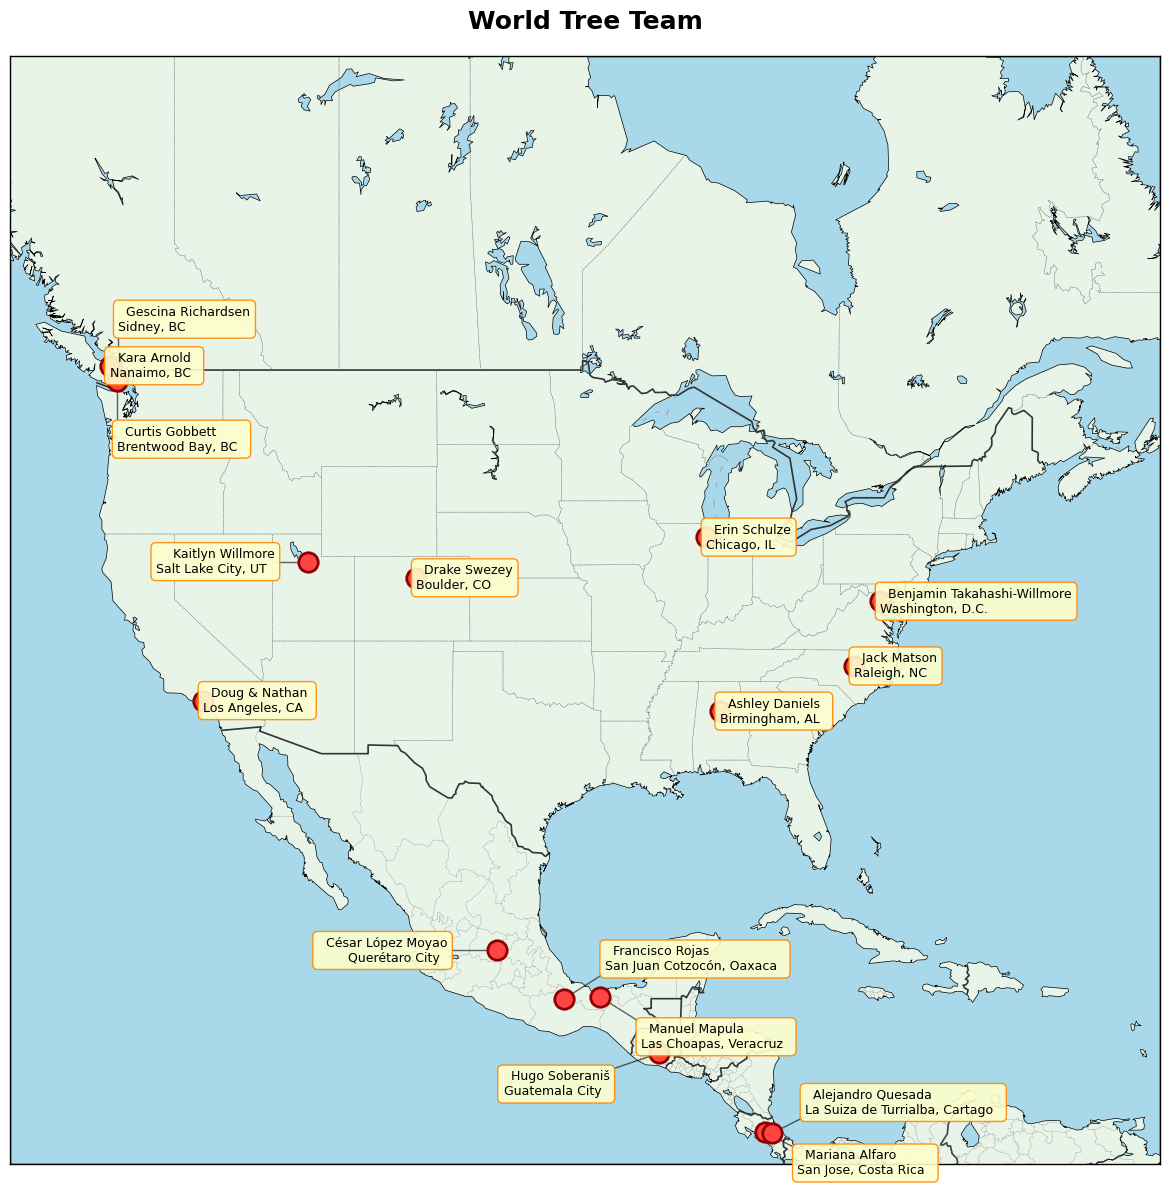


📍 Resumen de ubicaciones:
Total de miembros: 16

Por país:
  🇺🇸 USA: 7
  🇨🇦 Canadá: 3
  🇲🇽 México: 3
  🇨🇷 Costa Rica: 2
  🇬🇹 Guatemala: 1


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

# Coordenadas del equipo (lat, lon, offset_x, offset_y, ha, va)
# ha: 'left' o 'right' para alineación horizontal
# va: 'top', 'bottom', 'center' para alineación vertical
team_data = {
    "Erin Schulze\nChicago, IL": (41.88, -87.63, 0, 0, 'left', 'center'),
    "Drake Swezey\nBoulder, CO": (40.01, -105.27, 0, 0, 'left', 'center'),
    "Ashley Daniels\nBirmingham, AL": (33.52, -86.80, 0, 0, 'left', 'center'),
    "Gescina Richardsen\nSidney, BC": (48.65, -123.40, 0, 1.8, 'left', 'bottom'),
    "Hugo Soberaniš\nGuatemala City": (14.64, -90.51, -3, -1, 'right', 'top'),
    "Jack Matson\nRaleigh, NC": (35.78, -78.64, 0, 0, 'left', 'center'),
    "Curtis Gobbett\nBrentwood Bay, BC": (48.55, -123.47, 0, -1.8, 'left', 'top'),
    "Doug & Nathan\nLos Angeles, CA": (34.05, -118.24, 0, 0, 'left', 'center'),
    "Mariana Alfaro\nSan Jose, Costa Rica": (9.93, -84.08, 2, -1, 'left', 'top'),
    "Alejandro Quesada\nLa Suiza de Turrialba, Cartago": (9.88, -83.61, 2, 1, 'left', 'bottom'),
    "Benjamin Takahashi-Willmore\nWashington, D.C.": (38.91, -77.04, 0, 0, 'left', 'center'),
    "Kara Arnold\nNanaimo, BC": (49.17, -123.94, 0, 0, 'left', 'center'),
    "Kaitlyn Willmore\nSalt Lake City, UT": (40.76, -111.89, -2, 0, 'right', 'center'),
    "César López Moyao\nQuerétaro City": (20.59, -100.39, -3, 0, 'right', 'center'),
    "Francisco Rojas\nSan Juan Cotzocón, Oaxaca": (17.80, -96.30, 2.5, 1.5, 'left', 'bottom'),
    "Manuel Mapula\nLas Choapas, Veracruz": (17.92, -94.10, 2.5, -1.5, 'left', 'top')
}

# Crear mapa
plt.figure(figsize=(18, 12))
m = Basemap(projection='merc', resolution='l',
            llcrnrlat=8, urcrnrlat=60,
            llcrnrlon=-130, urcrnrlon=-60)

m.drawcoastlines(linewidth=0.5)
m.drawcountries(linewidth=1.2, color='#333333')
m.fillcontinents(color='#e8f4e8', lake_color='#a8d8ea')
m.drawmapboundary(fill_color='#a8d8ea')
m.drawstates(linewidth=0.3, color='gray', linestyle='--')

# Plotear ubicaciones
for label, (lat, lon, offset_x, offset_y, ha, va) in team_data.items():
    x, y = m(lon, lat)

    # Punto en el mapa
    m.plot(x, y, 'o', color='#ff4444', markersize=14,
           markeredgecolor='darkred', markeredgewidth=2, zorder=5)

    # Calcular posición del texto con offset
    x_text, y_text = m(lon + offset_x, lat + offset_y)

    # Si hay offset significativo, dibujar línea conectora
    if abs(offset_x) > 0.5 or abs(offset_y) > 0.5:
        m.plot([x, x_text], [y, y_text], 'k-', linewidth=1, alpha=0.6, zorder=4)

    # Texto con bbox
    plt.text(x_text, y_text, f'  {label}  ' if ha == 'left' else f'  {label}  ',
             fontsize=9, ha=ha, va=va,
             bbox=dict(boxstyle='round,pad=0.4',
                      facecolor='#ffffcc', alpha=0.9, edgecolor='#ff8800'),
             zorder=6)

plt.title(f'World Tree Team',
          fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Resumen por país/región
print("\n📍 Resumen de ubicaciones:")
print(f"Total de miembros: {len(team_data)}")
print("\nPor país:")
usa = sum(1 for label in team_data.keys() if any(state in label for state in ['IL', 'CO', 'AL', 'NC', 'CA', 'D.C.', 'UT']))
canada = sum(1 for label in team_data.keys() if 'BC' in label)
mexico = sum(1 for label in team_data.keys() if any(state in label for state in ['Querétaro', 'Oaxaca', 'Veracruz']))
costa_rica = sum(1 for label in team_data.keys() if 'Costa Rica' in label or 'Cartago' in label)
guatemala = sum(1 for label in team_data.keys() if 'Guatemala' in label)
print(f"  🇺🇸 USA: {usa}")
print(f"  🇨🇦 Canadá: {canada}")
print(f"  🇲🇽 México: {mexico}")
print(f"  🇨🇷 Costa Rica: {costa_rica}")
print(f"  🇬🇹 Guatemala: {guatemala}")

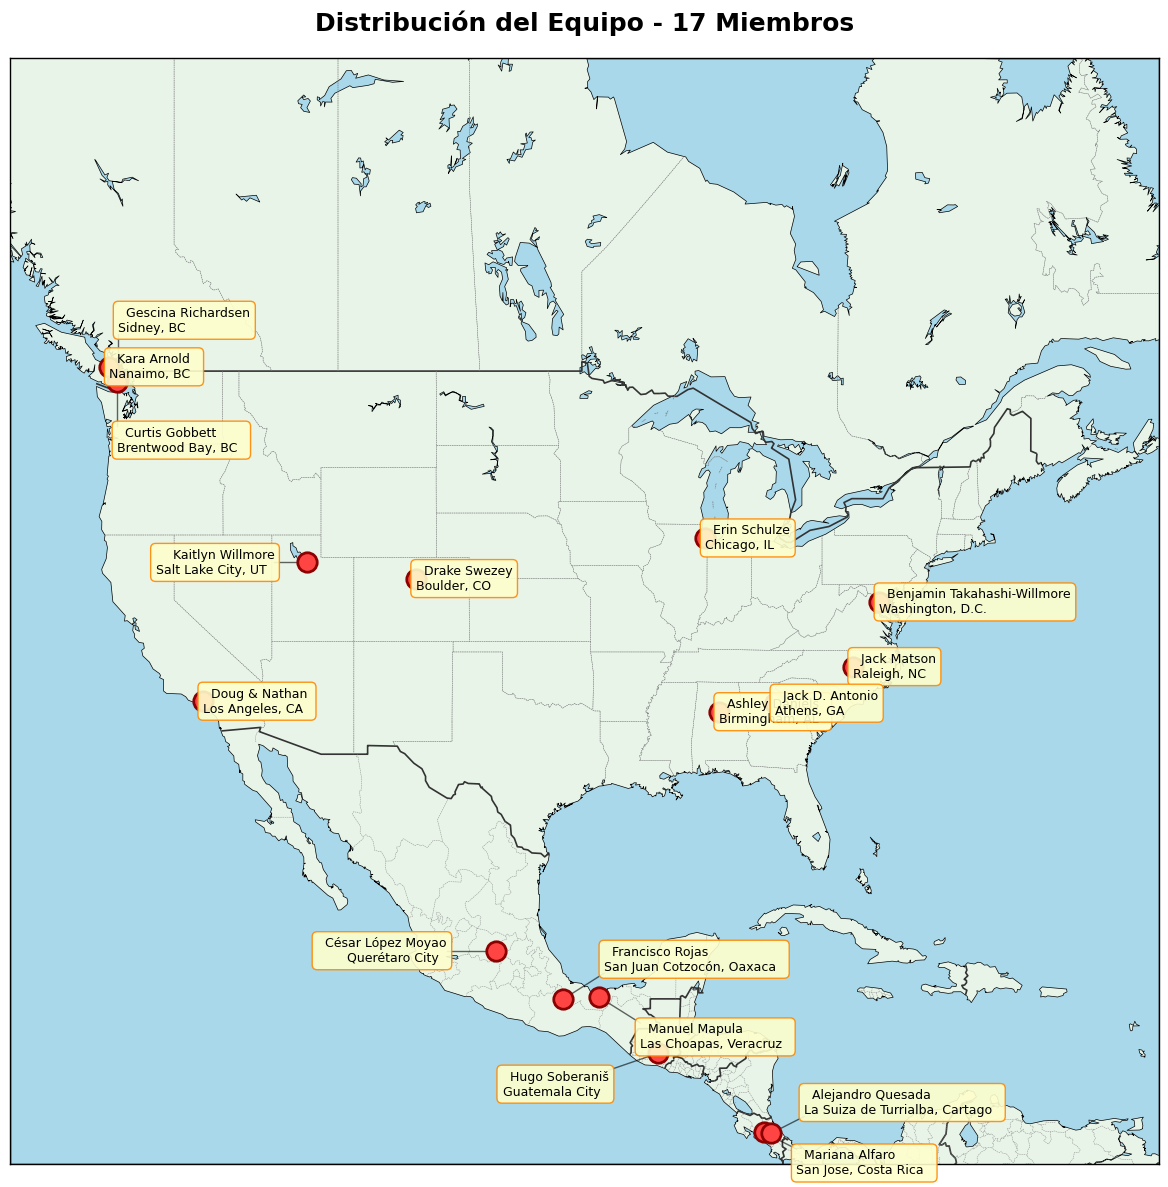


📍 Resumen de ubicaciones:
Total de miembros: 17

Por país:
  🇺🇸 USA: 8
  🇨🇦 Canadá: 3
  🇲🇽 México: 3
  🇨🇷 Costa Rica: 2
  🇬🇹 Guatemala: 1


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

# Coordenadas del equipo (lat, lon, offset_x, offset_y, ha, va)
# ha: 'left' o 'right' para alineación horizontal
# va: 'top', 'bottom', 'center' para alineación vertical
team_data = {
    "Erin Schulze\nChicago, IL": (41.88, -87.63, 0, 0, 'left', 'center'),
    "Drake Swezey\nBoulder, CO": (40.01, -105.27, 0, 0, 'left', 'center'),
    "Ashley Daniels\nBirmingham, AL": (33.52, -86.80, 0, 0, 'left', 'center'),
    "Gescina Richardsen\nSidney, BC": (48.65, -123.40, 0, 1.8, 'left', 'bottom'),
    "Hugo Soberaniš\nGuatemala City": (14.64, -90.51, -3, -1, 'right', 'top'),
    "Jack Matson\nRaleigh, NC": (35.78, -78.64, 0, 0, 'left', 'center'),
    "Curtis Gobbett\nBrentwood Bay, BC": (48.55, -123.47, 0, -1.8, 'left', 'top'),
    "Doug & Nathan\nLos Angeles, CA": (34.05, -118.24, 0, 0, 'left', 'center'),
    "Mariana Alfaro\nSan Jose, Costa Rica": (9.93, -84.08, 2, -1, 'left', 'top'),
    "Alejandro Quesada\nLa Suiza de Turrialba, Cartago": (9.88, -83.61, 2, 1, 'left', 'bottom'),
    "Benjamin Takahashi-Willmore\nWashington, D.C.": (38.91, -77.04, 0, 0, 'left', 'center'),
    "Kara Arnold\nNanaimo, BC": (49.17, -123.94, 0, 0, 'left', 'center'),
    "Kaitlyn Willmore\nSalt Lake City, UT": (40.76, -111.89, -2, 0, 'right', 'center'),
    "César López Moyao\nQuerétaro City": (20.59, -100.39, -3, 0, 'right', 'center'),
    "Francisco Rojas\nSan Juan Cotzocón, Oaxaca": (17.80, -96.30, 2.5, 1.5, 'left', 'bottom'),
    "Manuel Mapula\nLas Choapas, Veracruz": (17.92, -94.10, 2.5, -1.5, 'left', 'top'),
    "Jack D. Antonio\nAthens, GA": (33.95, -83.38, 0, 0, 'left', 'center')
}

# Crear mapa
plt.figure(figsize=(18, 12))
m = Basemap(projection='merc', resolution='l',
            llcrnrlat=8, urcrnrlat=60,
            llcrnrlon=-130, urcrnrlon=-60)

m.drawcoastlines(linewidth=0.5)
m.drawcountries(linewidth=1.2, color='#333333')
m.fillcontinents(color='#e8f4e8', lake_color='#a8d8ea')
m.drawmapboundary(fill_color='#a8d8ea')
m.drawstates(linewidth=0.3, color='gray', linestyle='--')

# Plotear ubicaciones
for label, (lat, lon, offset_x, offset_y, ha, va) in team_data.items():
    x, y = m(lon, lat)

    # Punto en el mapa
    m.plot(x, y, 'o', color='#ff4444', markersize=14,
           markeredgecolor='darkred', markeredgewidth=2, zorder=5)

    # Calcular posición del texto con offset
    x_text, y_text = m(lon + offset_x, lat + offset_y)

    # Si hay offset significativo, dibujar línea conectora
    if abs(offset_x) > 0.5 or abs(offset_y) > 0.5:
        m.plot([x, x_text], [y, y_text], 'k-', linewidth=1, alpha=0.6, zorder=4)

    # Texto con bbox
    plt.text(x_text, y_text, f'  {label}  ' if ha == 'left' else f'  {label}  ',
             fontsize=9, ha=ha, va=va,
             bbox=dict(boxstyle='round,pad=0.4',
                      facecolor='#ffffcc', alpha=0.9, edgecolor='#ff8800'),
             zorder=6)

plt.title(f'Distribución del Equipo - {len(team_data)} Miembros',
          fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Resumen por país/región
print("\n📍 Resumen de ubicaciones:")
print(f"Total de miembros: {len(team_data)}")
print("\nPor país:")
usa = sum(1 for label in team_data.keys() if any(state in label for state in ['IL', 'CO', 'AL', 'NC', 'CA', 'D.C.', 'UT', 'GA']))
canada = sum(1 for label in team_data.keys() if 'BC' in label)
mexico = sum(1 for label in team_data.keys() if any(state in label for state in ['Querétaro', 'Oaxaca', 'Veracruz']))
costa_rica = sum(1 for label in team_data.keys() if 'Costa Rica' in label or 'Cartago' in label)
guatemala = sum(1 for label in team_data.keys() if 'Guatemala' in label)
print(f"  🇺🇸 USA: {usa}")
print(f"  🇨🇦 Canadá: {canada}")
print(f"  🇲🇽 México: {mexico}")
print(f"  🇨🇷 Costa Rica: {costa_rica}")
print(f"  🇬🇹 Guatemala: {guatemala}")

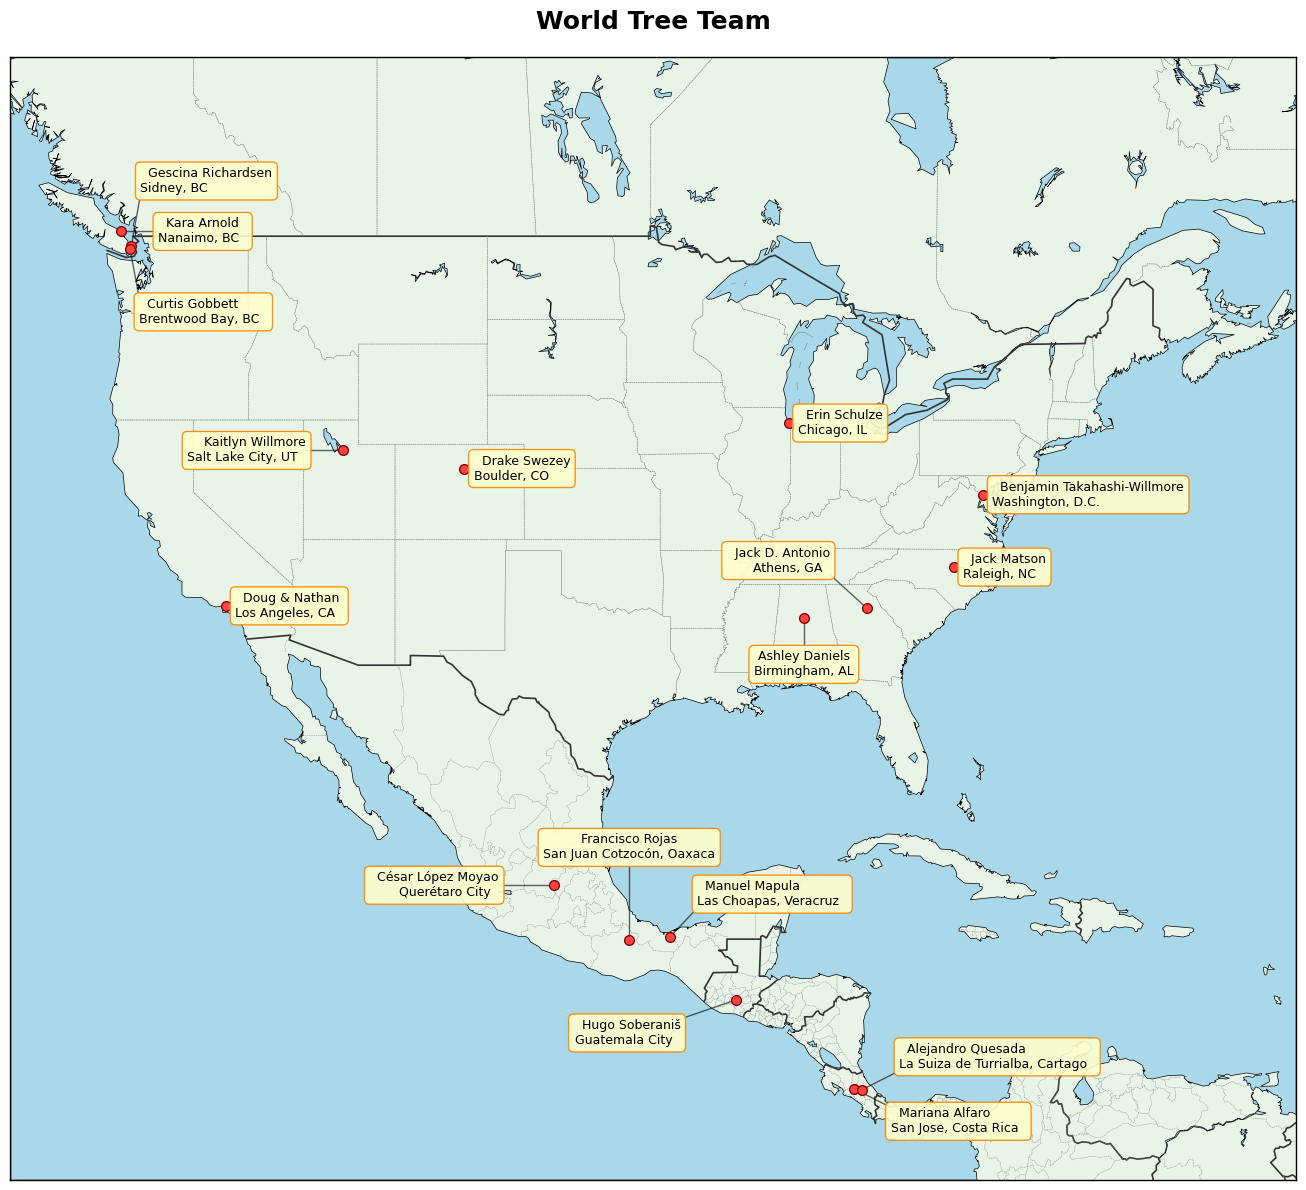


📍 Resumen de ubicaciones:
Total de miembros: 17

Por país:
  🇺🇸 USA: 8
  🇨🇦 Canadá: 3
  🇲🇽 México: 3
  🇨🇷 Costa Rica: 2
  🇬🇹 Guatemala: 1


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

# Coordenadas del equipo (lat, lon, offset_x, offset_y, ha, va)
# ha: 'left' o 'right' para alineación horizontal
# va: 'top', 'bottom', 'center' para alineación vertical
team_data = {
    "Erin Schulze\nChicago, IL": (41.88, -87.63, 0.5, 0, 'left', 'center'),
    "Drake Swezey\nBoulder, CO": (40.01, -105.27, 0.5, 0, 'left', 'center'),
    "Ashley Daniels\nBirmingham, AL": (33.52, -86.80, 0, -1.5, 'center', 'top'),
    "Gescina Richardsen\nSidney, BC": (48.65, -123.40, 0.5, 1.8, 'left', 'bottom'),
    "Hugo Soberaniš\nGuatemala City": (14.64, -90.51, -3, -1, 'right', 'top'),
    "Jack Matson\nRaleigh, NC": (35.78, -78.64, 0.5, 0, 'left', 'center'),
    "Curtis Gobbett\nBrentwood Bay, BC": (48.55, -123.47, 0.5, -1.8, 'left', 'top'),
    "Doug & Nathan\nLos Angeles, CA": (34.05, -118.24, 0.5, 0, 'left', 'center'),
    "Mariana Alfaro\nSan Jose, Costa Rica": (9.93, -84.08, 2, -1, 'left', 'top'),
    "Alejandro Quesada\nLa Suiza de Turrialba, Cartago": (9.88, -83.61, 2, 1, 'left', 'bottom'),
    "Benjamin Takahashi-Willmore\nWashington, D.C.": (38.91, -77.04, 0.5, 0, 'left', 'center'),
    "Kara Arnold\nNanaimo, BC": (49.17, -123.94, 2, 0, 'left', 'center'),
    "Kaitlyn Willmore\nSalt Lake City, UT": (40.76, -111.89, -2, 0, 'right', 'center'),
    "César López Moyao\nQuerétaro City": (20.59, -100.39, -3, 0, 'right', 'center'),
    "Francisco Rojas\nSan Juan Cotzocón, Oaxaca": (17.80, -96.30, 0, 4, 'center', 'bottom'),
    "Manuel Mapula\nLas Choapas, Veracruz": (17.92, -94.10, 1.5, 1.5, 'left', 'bottom'),
    "Jack D. Antonio\nAthens, GA": (33.95, -83.38, -2, 1.5, 'right', 'bottom')
}

# Crear mapa
plt.figure(figsize=(18, 12))
m = Basemap(projection='merc', resolution='l',
            llcrnrlat=5, urcrnrlat=55,
            llcrnrlon=-130, urcrnrlon=-60)

m.drawcoastlines(linewidth=0.5)
m.drawcountries(linewidth=1.2, color='#333333')
m.fillcontinents(color='#e8f4e8', lake_color='#a8d8ea')
m.drawmapboundary(fill_color='#a8d8ea')
m.drawstates(linewidth=0.3, color='gray', linestyle='--')

# Plotear ubicaciones
for label, (lat, lon, offset_x, offset_y, ha, va) in team_data.items():
    x, y = m(lon, lat)

    # Punto en el mapa (tamaño reducido a la mitad: de 14 a 7)
    m.plot(x, y, 'o', color='#ff4444', markersize=7,
           markeredgecolor='darkred', markeredgewidth=1, zorder=5)

    # Calcular posición del texto con offset
    x_text, y_text = m(lon + offset_x, lat + offset_y)

    # Si hay offset significativo, dibujar línea conectora
    if abs(offset_x) > 0.3 or abs(offset_y) > 0.3:
        m.plot([x, x_text], [y, y_text], 'k-', linewidth=1, alpha=0.6, zorder=4)

    # Texto con bbox
    plt.text(x_text, y_text, f'  {label}  ' if ha == 'left' else (f'  {label}  ' if ha == 'right' else f'{label}'),
             fontsize=9, ha=ha, va=va,
             bbox=dict(boxstyle='round,pad=0.4',
                      facecolor='#ffffcc', alpha=0.9, edgecolor='#ff8800'),
             zorder=6)

plt.title(f'World Tree Team',
          fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Resumen por país/región
print("\n📍 Resumen de ubicaciones:")
print(f"Total de miembros: {len(team_data)}")
print("\nPor país:")
usa = sum(1 for label in team_data.keys() if any(state in label for state in ['IL', 'CO', 'AL', 'NC', 'CA', 'D.C.', 'UT', 'GA']))
canada = sum(1 for label in team_data.keys() if 'BC' in label)
mexico = sum(1 for label in team_data.keys() if any(state in label for state in ['Querétaro', 'Oaxaca', 'Veracruz']))
costa_rica = sum(1 for label in team_data.keys() if 'Costa Rica' in label or 'Cartago' in label)
guatemala = sum(1 for label in team_data.keys() if 'Guatemala' in label)
print(f"  🇺🇸 USA: {usa}")
print(f"  🇨🇦 Canadá: {canada}")
print(f"  🇲🇽 México: {mexico}")
print(f"  🇨🇷 Costa Rica: {costa_rica}")
print(f"  🇬🇹 Guatemala: {guatemala}")